# IND320 Part 4 · Forecasting reservoir filling

- [Public GitHub repository](https://github.com/Yangocito/ind320-reservoir-dashboard-yangocito)
- [Streamlit dashboard](https://ind320-reservoir-dashboard-yangocito-jqlwog89hlllmliwtrhsmd.streamlit.app/)

This notebook uses the same data and forecast functions as Streamlit. The worked example is NO3. Run it with the packages in `requirements-notebook.txt`.

## 1. Set up the environment and data sources

In [1]:
from pathlib import Path
import sys

# Support launching Jupyter in either the repository or notebooks directory.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, display

from src.forecast import (DEFAULT, WEATHER_LABELS, backtest, exchange_rates,
                          forecast_filling, period_weather, reservoir_observations,
                          rolling_correlation)
from src.utils import fetch_reservoirs
from src.weather import daily_weather, download_weather, sample_locations

reservoirs = fetch_reservoirs()
filling = reservoir_observations(reservoirs, ("EL", 3))
print(f"NVE returned {len(reservoirs):,} rows. NO3 has {filling.count():,} weekly observations.")

NVE returned 14,976 rows. NO3 has 1,664 weekly observations.


## 2. Exchange rates from Norges Bank

The business-day spot series gives Norwegian kroner per EUR and USD. Holidays and weekends are left absent. The app also makes this request directly.

BASE_CUR,EUR,USD
date,,
2026-01-02,11.7985,10.0661
2026-01-05,11.7795,10.0990
2026-01-06,11.7285,10.0184
2026-01-07,11.7585,10.0638
2026-01-08,11.7935,10.1015
2026-01-09,11.7765,10.1155
2026-01-12,11.7445,10.0449


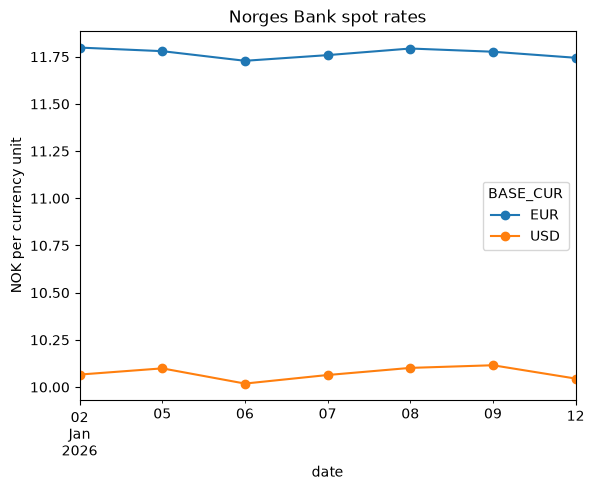

In [2]:
# A small live API request demonstrates the expected shape and units.
example_fx = exchange_rates("2026-01-02", "2026-01-12")
assert list(example_fx.columns) == ["EUR", "USD"] and not example_fx.empty
assert (example_fx.index.dayofweek < 5).all() and example_fx.notna().all().all()
display(example_fx)

ax = example_fx.plot(marker="o", ylabel="NOK per currency unit", title="Norges Bank spot rates")
plt.show()

## 3. Time zones and publication dates

| Source | Returned time | Alignment used |
|---|---|---|
| [NVE Magasinstatistikk](https://api.nve.no/doc/magasinstatistikk/) and [reporting schedule](https://www.nve.no/nytt-fra-nve/rapporter-vassmagasinstatistikk/) | Sunday observation date and ISO week/year. Weekly results are normally published Wednesday at 13:00 Norwegian time, with possible schedule changes. | Reconstruct the Sunday from ISO week/year. Use a three-day publication delay as a date-level approximation. |
| [ENTSO-E](https://transparency.entsoe.eu/content/static_content/Static%20content/knowledge%20base/Subscription%20Configuration%20User%20Guide%20v0.1.pdf) | UTC timestamps for physical-flow intervals. Spark in Part 2 stores sums by UTC day in MongoDB. | Keep the daily series in UTC. A Norwegian daily total would require converting the original subdaily measurements to Oslo time **before** summing. Flow totals remain in the Flow page and are not used here as model inputs. |
| [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) | Hourly data requested as GMT. Daily requests let us choose date boundaries. | Keep hourly weather in UTC for regular spacing in SATV and LOF. Request Europe/Oslo daily values for calendar aggregation. The app leaves a seven-day margin for the ERA5 archive near today. |
| [Norges Bank](https://www.norges-bank.no/en/topics/Statistics/open-data/guide-data-warehouse/) | Day labels for business-day exchange rates. The API metadata gives the ECB fixing convention. | Keep them as dates and average the available observations within each period. Avoid filling weekends and holidays with repeated rates. |

The weekly joins use a Sunday label. For forecasts, the previous completed input period supplies the external variables. The model uses archived data as currently published, so backtests are not exact historical snapshots of what each provider returned that day. The NVE approximation is date-level and does not model an intraday cutoff or holidays.

In [3]:
# Show the ISO label and compare UTC versus Oslo around both 2024 DST changes.
recent = reservoirs.loc[reservoirs.area_type.eq("EL") & reservoirs.area_number.eq(3),
                        ["date", "iso_year", "iso_week"]].tail(5).copy()
recent["ISO Sunday"] = filling.index[-len(recent):]
display(recent)

rows = []
for label, first, last in [("Spring", "2024-03-30", "2024-04-01"),
                           ("Autumn", "2024-10-26", "2024-10-28")]:
    sample = sample_locations(count=1, regions=["NO3"])
    hourly = download_weather("NO3", first, last, sample)
    transition_day = pd.Timestamp(first).date() + pd.Timedelta(days=1)
    local_count = (hourly.index.tz_convert("Europe/Oslo").date == transition_day).sum()
    utc_count = (hourly.index.date == transition_day).sum()
    rows.append((label, transition_day, utc_count, local_count))
display(pd.DataFrame(rows, columns=["Transition", "Date", "UTC hours", "Oslo hours"]))

,date,iso_year,iso_week,ISO Sunday
14933,2026-10-25,2026,43,2026-10-25
14942,2026-11-01,2026,44,2026-11-01
14951,2026-11-08,2026,45,2026-11-08
14960,2026-11-15,2026,46,2026-11-15
14969,2026-11-22,2026,47,2026-11-22


,Transition,Date,UTC hours,Oslo hours
0,Spring,2024-03-31,24,23
1,Autumn,2024-10-27,24,25


## 4. Navigation sketch

The map and sidebar were sketched first. The shared region, date and forecast horizon sit in the sidebar. Display and model controls stay on the pages that use them.

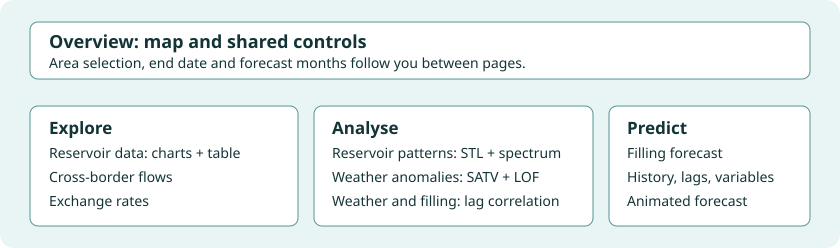

In [4]:
# Embed the sketch in the output so it also appears in the HTML export.
display(SVG(filename=ROOT / "notebooks" / "navigation.svg"))

## 5. Weather and filling: sliding-window correlation

I test temperature, precipitation and humidity against weekly changes in filling. A positive lag tests whether earlier weather is associated with later reservoir changes. The 12-week window tracks seasonal changes faster than the 26-week window.

,Property,Lag,Window,Median,Min,Max
0,Temperature (°C),0,12,0.672,-0.687,0.952
1,Temperature (°C),0,26,0.695,-0.168,0.916
2,Temperature (°C),2,12,0.082,-0.830,0.924
3,Temperature (°C),2,26,0.441,-0.426,0.815
4,Temperature (°C),4,12,0.104,-0.886,0.821
5,Temperature (°C),4,26,0.348,-0.782,0.778
6,Precipitation (mm),0,12,0.632,-0.733,0.952
7,Precipitation (mm),0,26,0.255,-0.534,0.840
8,Precipitation (mm),2,12,-0.053,-0.651,0.634
9,Precipitation (mm),2,26,-0.158,-0.567,0.428


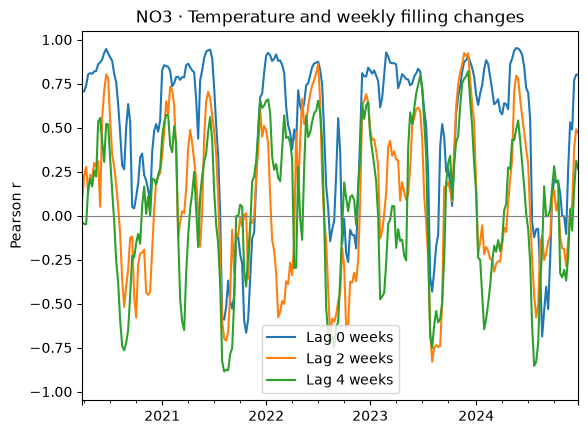

In [5]:
# Keep dates fixed for a reproducible comparison in the notebook.
weather = daily_weather("NO3", "2018-01-01", "2025-04-09")
fx = exchange_rates("2018-01-01", "2025-04-09")
drivers = weather.join(fx, how="outer")
weekly_weather = period_weather(weather, "W-SUN", hourly=False)
correlations = {}
summary = []
for variable in WEATHER_LABELS:
    for lag in (0, 2, 4):
        for window in (12, 26):
            series = rolling_correlation(filling.loc["2020":"2024"], weekly_weather[variable],
                                         window, lag).dropna()
            summary.append((WEATHER_LABELS[variable], lag, window, series.median(),
                            series.min(), series.max()))
            if variable == "temperature_2m" and window == 12:
                correlations[f"Lag {lag} weeks"] = series
display(pd.DataFrame(summary, columns=["Property", "Lag", "Window", "Median", "Min", "Max"]).round(3))
ax = pd.DataFrame(correlations).plot(ylabel="Pearson r", ylim=(-1.05, 1.05),
                                     title="NO3 · Temperature and weekly filling changes")
ax.axhline(0, color="grey", linewidth=0.8)
plt.show()

## 6. River model and validation

For each forecast lead a River linear model learns the change from the last observed filling to the future level. It takes filling lags, annual calendar terms and any selected external predictors at the origin. Future weather and exchange observations are never required. Training pairs that lack required data are skipped. Predictions are clipped to 0–100%. I compare with persistence and a seasonal baseline that reuses the corresponding period from the previous year.

In [6]:
# Refit at four validation origins. Keep two later origins for a final holdout.
origins = pd.to_datetime(["2024-01-10", "2024-04-10", "2024-07-10", "2024-10-09",
                          "2025-01-08", "2025-04-09"])
settings = {
    "Weekly · 8y, 4 lags": DEFAULT,
    "Weekly · 5y, 4 lags": DEFAULT | {"history_years": 5},
    "Weekly · 8y, 8 lags": DEFAULT | {"lags": 8},
    "Weekly · faster learning": DEFAULT | {"rate": 0.02},
    "Monthly · 8y, 2 lags": DEFAULT | {"resolution": "Monthly", "lags": 2},
    "Monthly · faster learning": DEFAULT | {"resolution": "Monthly", "lags": 2, "rate": 0.02},
    "Weekly · weather": DEFAULT | {"history_years": 5, "sources": ("temperature_2m", "precipitation")},
    "Weekly · currencies": DEFAULT | {"history_years": 5, "sources": ("EUR", "USD")},
}

# Score both resolutions against the same last Sunday of each forecast month.
validation = {key: backtest(filling, drivers, options, origins[:4], common_monthly=True)
              for key, options in settings.items()}
results = pd.DataFrame({key: table.mean(numeric_only=True)
                        for key, table in validation.items()}).T.sort_values("River")
display(results.round(3))
best = results.index[0]
print("Validation winner:", best)
holdout = backtest(filling, drivers, settings[best], origins[4:], common_monthly=True)
display(holdout.round(3))
print("Holdout mean absolute error (percentage points):", holdout[["River", "Persistence", "Seasonal naive"]].mean().round(2).to_dict())

,River,Persistence,Seasonal naive,seconds,predictions
"Weekly · 8y, 4 lags",9.997,15.147,8.411,0.211,3.0
"Weekly · 8y, 8 lags",10.223,15.147,8.411,0.227,3.0
Weekly · faster learning,10.588,15.147,8.411,0.196,3.0
"Weekly · 5y, 4 lags",11.054,15.147,8.411,0.124,3.0
Weekly · weather,11.069,15.147,8.411,0.142,3.0
Weekly · currencies,11.191,15.147,8.411,0.140,3.0
Monthly · faster learning,11.347,16.474,9.120,0.015,3.0
"Monthly · 8y, 2 lags",13.074,16.474,9.120,0.015,3.0


Validation winner: Weekly · 8y, 4 lags


,River,Persistence,Seasonal naive,seconds,predictions
origin,,,,,
2025-01-08,5.339,19.512,32.389,0.200,3
2025-04-09,9.462,14.959,20.326,0.204,3


Holdout mean absolute error (percentage points): {'River': 7.4, 'Persistence': 17.24, 'Seasonal naive': 26.36}


,River,Persistence,Seasonal naive,Training pairs
Date,,,,
2025-04-13,48.63,49.1,19.37,414
2025-04-20,48.47,49.1,17.67,413
2025-04-27,48.63,49.1,14.75,412
2025-05-04,49.14,49.1,18.37,411
2025-05-11,50.02,49.1,25.24,410


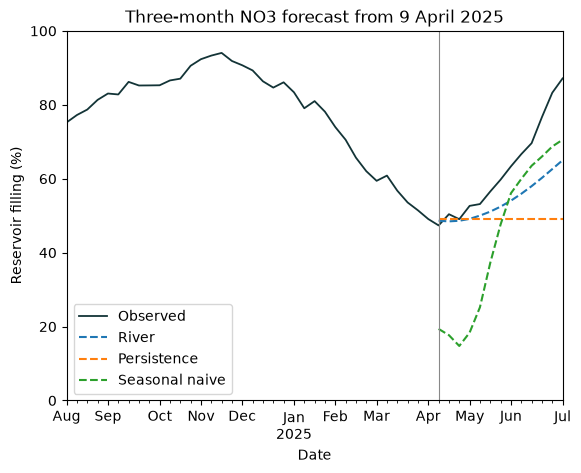

In [7]:
# Forecast at a fixed date so the figure can be reproduced and checked.
origin = pd.Timestamp("2025-04-09")
prediction = forecast_filling(filling, drivers, as_of=origin, horizon_months=3, **settings[best])
display(prediction.head().round(2))

ax = filling.loc["2024-08-01":prediction.index[-1]].plot(
    color="#133437", linewidth=1.3, label="Observed", ylabel="Reservoir filling (%)",
    title="Three-month NO3 forecast from 9 April 2025")
prediction[["River", "Persistence", "Seasonal naive"]].plot(ax=ax, linestyle="--")
ax.axvline(origin, color="#888888", linewidth=0.8)
ax.set_ylim(0, 100)
ax.legend()
plt.show()

## 7. Work log

I started Part 4 by sketching the dashboard navigation around the map. The earlier table and plots were split across pages, so I put the measurement chart and downloadable table on the same page. I moved the reusable Python modules into `src/` and gathered all four notebooks in `notebooks/`. The sidebar now carries the selected area and date through the dashboard, while the weather fields and model parameters stay with their own pages. I converted the previous boundaries to GeoJSON. The water polygons come from the earlier grouping of administrative polygons, so I labelled them as approximate.

In Jupyter I checked the Norges Bank response by requesting EUR and USD together. Dates were a bigger issue than I expected. NVE gives a Sunday reporting label, but the result is normally published on Wednesday. ENTSO-E flows are already daily UTC totals in MongoDB. The weather API can return UTC hours or Oslo daily values. Comparing the spring and autumn transitions gave 23 and 25 Oslo hours while UTC stayed at 24. This is why I use UTC for hourly anomaly detection and local calendar weeks for weather correlations.

For NO3, the 12-week temperature correlation at lag zero ranged from about −0.69 to +0.95 over 2020–2024. Its median was about 0.67, but it fell to about 0.08 when temperature led by two weeks. Precipitation also changed sign depending on the window and lag. This makes me cautious about using a high correlation in one season as evidence that the same variable will help a forecast several months ahead.

I compared weekly and monthly River models on the same month-ending reservoir observations. The weekly model with eight years of history and four lags had the lowest validation error among these configurations, about 10.0 percentage points. The two later holdouts averaged about 7.4 points. The October origin was difficult and persistence did better there. Monthly fitting was faster but gave fewer points for the animated chart. Weather and currencies are available as optional inputs, but the tested combinations did not improve on the weekly default.

For Streamlit I chose **waiting time** and **error handling** as bonus tasks. Repeated API calls and model fits are cached where possible, weather pages let the user decide when to load a heavier dataset, and the app reports missing records or connection failures near the relevant chart. The forecast animation lets a viewer step through the horizon and compare each date with the two baselines.

## 8. AI usage

I used ChatGPT to help design the navigation, implement and refactor Python code, draft the notebook text and run checks. Results and timing tables in this notebook are generated from the code cells and the actual public API responses.